<a href="https://colab.research.google.com/github/weagan/Grassman-manifold/blob/main/attn_vs_grassmann_k5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard Causal Attention vs. Causal Grassmann Subspace Blocks (`L = 20`, `2 Layers`, `K = 5`)

This notebook compares two matched 2-layer causal sequence models on a sequence length of **20 tokens**:
1. **Standard Causal Attention Network:** `RMSNorm -> Causal Multi-Head Self-Attention -> RMSNorm -> SwiGLU FFN`
2. **Causal Grassmann Network (`K = 5`):** `RMSNorm -> Causal Grassmann Plücker Mixing Gr(2, r) -> RMSNorm -> SwiGLU FFN`

### Left-to-Right Structural Pipeline
```text
x: H^{(0)} ∈ ℝ^{B × 20 × d}
  ├──► [ Model A ] Block 1 (Causal Attn + SwiGLU) ──► Block 2 (Causal Attn + SwiGLU) ──► Logits
  └──► [ Model B ] Block 1 (Grassmann K=5 + SwiGLU) ─► Block 2 (Grassmann K=5 + SwiGLU) ─► Logits
```
Both models are benchmarked side-by-side on parameter counts, forward/backward latency, and a synthetic multi-hop causal associative recall task (`L = 20`) where exact lookback distances test the receptive field of `K = 5` dilated offsets (`Δ = {1, 2, 4, 8, 16}`).

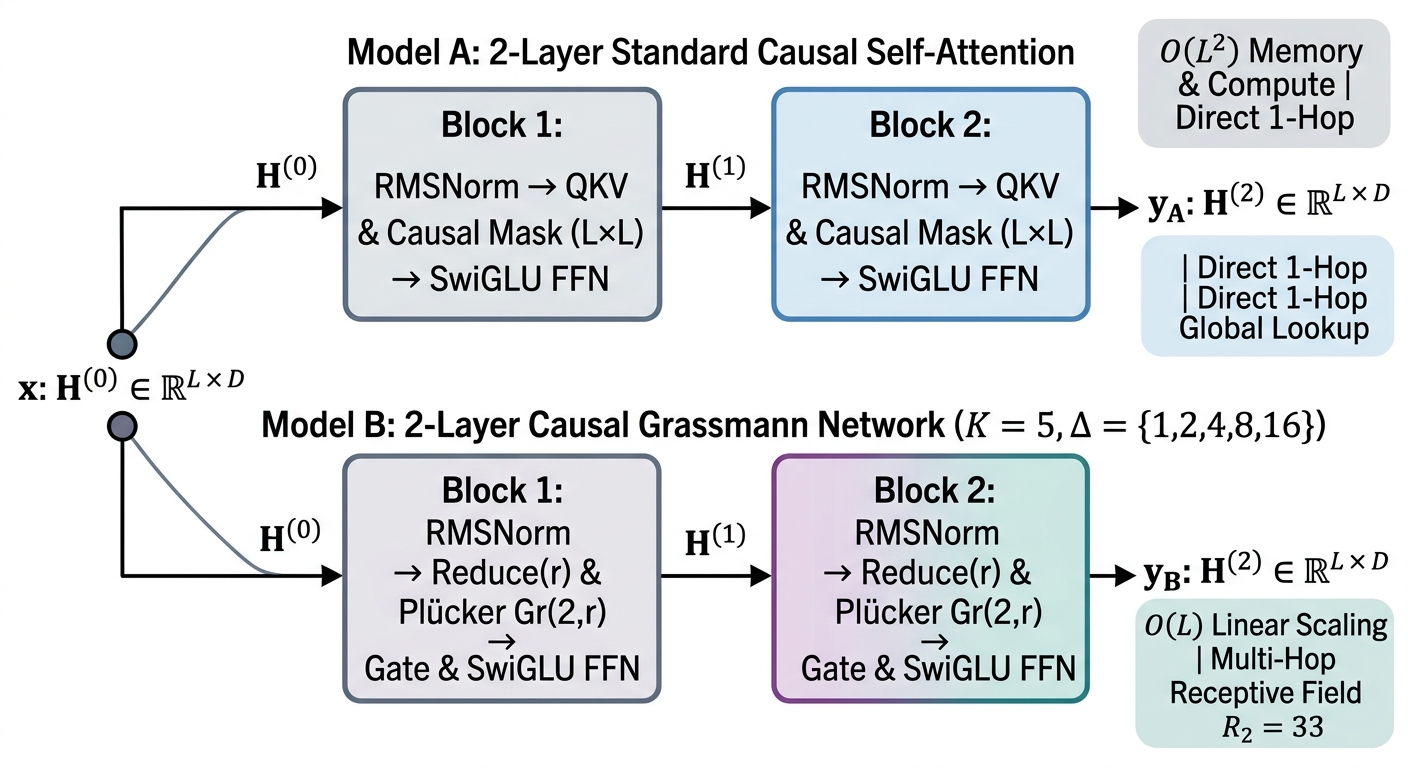


### 1. Environment & Platform Secrets Setup
* **`load_platform_secret`:** A cross-platform helper function that retrieves API keys (such as `HF_TOKEN`) from Google Colab `userdata`, Kaggle `UserSecretsClient`, or standard OS environment variables without raising errors if keys are unset.
* **Hardware Check:** Automatically detects GPU availability via `torch.cuda.is_available()` and sets the execution device to `cuda` or `cpu`.


In [1]:
# 1. Environment & Platform Secrets Setup (Google Colab & Kaggle Compatible)
import os
import time
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def load_platform_secret(secret_name: str, default: str = "") -> str:
    """Safely retrieves a secret from Google Colab, Kaggle, or environment variables."""
    # 1. Try Google Colab Secrets
    try:
        from google.colab import userdata
        val = userdata.get(secret_name)
        if val:
            os.environ[secret_name] = val
            return val
    except Exception:
        pass

    # 2. Try Kaggle Secrets
    try:
        from kaggle_secrets import UserSecretsClient
        val = UserSecretsClient().get_secret(secret_name)
        if val:
            os.environ[secret_name] = val
            return val
    except Exception:
        pass

    # 3. Fallback to OS environment
    return os.environ.get(secret_name, default)

# Optional HF_TOKEN / WANDB_API_KEY retrieval without throwing errors if unset
hf_token = load_platform_secret("HF_TOKEN")
print(f"Platform secret check complete | HF_TOKEN configured: {bool(hf_token)}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print(f"Running on device: {device}")

Platform secret check complete | HF_TOKEN configured: True
Running on device: cpu



### 2. Shared Building Blocks

* **`RMSNorm` (Root Mean Square Normalization):**
  An alternative to LayerNorm that scales the hidden states without re-centering them (i.e., it does not subtract the mean), saving computational overhead:
  $$\text{RMSNorm}(x) = \frac{x}{\sqrt{\frac{1}{d}\sum_{i=1}^{d} x_i^2 + \epsilon}} \odot \gamma$$
  
* **`SwiGLUFFN` (Swish-Gated Linear Unit FFN):**
  A high-performance feed-forward network block common in state-of-the-art LLMs (e.g., LLaMA). It uses a multiplicative gating mechanism:
  $$\text{SwiGLU}(x) = \Big(\text{SiLU}(x W_{g}) \odot (x W_{u})\Big) W_{d}$$

In [2]:
# 2. Shared Building Blocks: RMSNorm and SwiGLU FFN
class RMSNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d_model))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        rms = torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (x / rms) * self.weight


class SwiGLUFFN(nn.Module):
    """SwiGLU(x) = (SiLU(x W_g) * (x W_u)) W_d"""
    def __init__(self, d_model: int, d_ff: int):
        super().__init__()
        self.w_g = nn.Linear(d_model, d_ff, bias=False)
        self.w_u = nn.Linear(d_model, d_ff, bias=False)
        self.w_d = nn.Linear(d_ff, d_model, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.w_d(F.silu(self.w_g(x)) * self.w_u(x))


### 3. Architecture 1: Standard Causal Self-Attention

* **`CausalSelfAttention`:**
  Implements standard Multi-Head Attention. It projects inputs $x$ into Query ($q$), Key ($k$), and Value ($v$) states, computes scaled dot-product attention scores, and applies an upper-triangular mask matrix filled with $-\infty$ at indices where $t' > t$ to prevent looking into the future.
* **`StandardAttnBlock` & `StandardAttnLM`:**
  Chains the attention block and SwiGLU FFN with pre-normalization residual connections. The Language Model class (`StandardAttnLM`) adds learned token and absolute position embeddings before passing inputs through the stacked blocks.


### Architecture 1: Pipeline Diagram (2 Layers, Horizontal)

```text
Input ──► [Embeddings] ──► x_0 ──► [ Layer 1: RMSNorm ──► CausalSelfAttention ──(+) ──► RMSNorm ──► SwiGLUFFN ──(+) ] ──► x_1 ──► [ Layer 2: RMSNorm ──► CausalSelfAttention ──(+) ──► RMSNorm ──► SwiGLUFFN ──(+) ] ──► [RMSNorm] ──► [LM Head] ──► Logits
                           │                                              ▲     │                                              ▲
                           └─────────────────── Causal Residual ──────────┘     └─────────────────── FFN Residual ─────────────┘
```

In [3]:
# 3. Architecture 1: Standard Causal Self-Attention Network (2 Layers)
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.o_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, D = x.shape
        qkv = self.qkv(x).view(B, L, 3, self.n_heads, self.d_head)
        q, k, v = qkv.unbind(dim=2)
        q = q.transpose(1, 2)  # (B, H, L, d_head)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        causal_mask = torch.triu(torch.ones(L, L, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(causal_mask, float("-inf"))
        attn = F.softmax(scores, dim=-1)

        out = (attn @ v).transpose(1, 2).contiguous().view(B, L, D)
        return self.o_proj(out)


class StandardAttnBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_ff: int):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads)
        self.norm2 = RMSNorm(d_model)
        self.ffn = SwiGLUFFN(d_model, d_ff)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


class StandardAttnLM(nn.Module):
    def __init__(self, vocab_size: int, max_len: int, d_model: int, n_heads: int, d_ff: int, n_layers: int = 2):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([StandardAttnBlock(d_model, n_heads, d_ff) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, L = idx.shape
        pos = torch.arange(L, device=idx.device).unsqueeze(0)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.norm_f(x))


### 4. Architecture 2: Causal Grassmann Subspace Mixing

* **`CausalGrassmannMixer`:**
  Replaces pairwise token attention with geometric mixing on the Grassmann manifold $\text{Gr}(2, r)$ using Plücker coordinates:
  1. **Rank Reduction:** Projects the $D$-dimensional input down to a low-rank representation $z$ of size $r=16$.
  2. **Dilated Causal Pairing:** Uses $K=5$ exponentially dilated causal offsets $\Delta = \{1, 2, 4, 8, 16\}$ to pair current state $z_t$ with past states $z_{t-\delta}$.
  3. **Plücker Coordinate Embedding:** Computes the skew-symmetric wedge product $(z_{t, i} z_{t-\delta, j} - z_{t, j} z_{t-\delta, i})$ and normalizes the resulting vector onto a unit hypersphere.
  4. **Projection & Gated Fusion:** Concatenates coordinates across all offsets, projects back to $D$, and fuses the result back into the residual stream via a learned sigmoid gate.


### Architecture 2: Pipeline Diagram (2 Layers, Horizontal)

```text
Input ──► [Embeddings] ──► x_0 ──► [ Layer 1: RMSNorm ──► CausalGrassmannMixer ──(+) ──► RMSNorm ──► SwiGLUFFN ──(+) ] ──► x_1 ──► [ Layer 2: RMSNorm ──► CausalGrassmannMixer ──(+) ──► RMSNorm ──► SwiGLUFFN ──(+) ] ──► [RMSNorm] ──► [LM Head] ──► Logits
                           │                                                 ▲     │                                                 ▲
                           └─────────────────── Grassmann Residual ──────────┘     └─────────────────── FFN Residual ────────────────┘
```

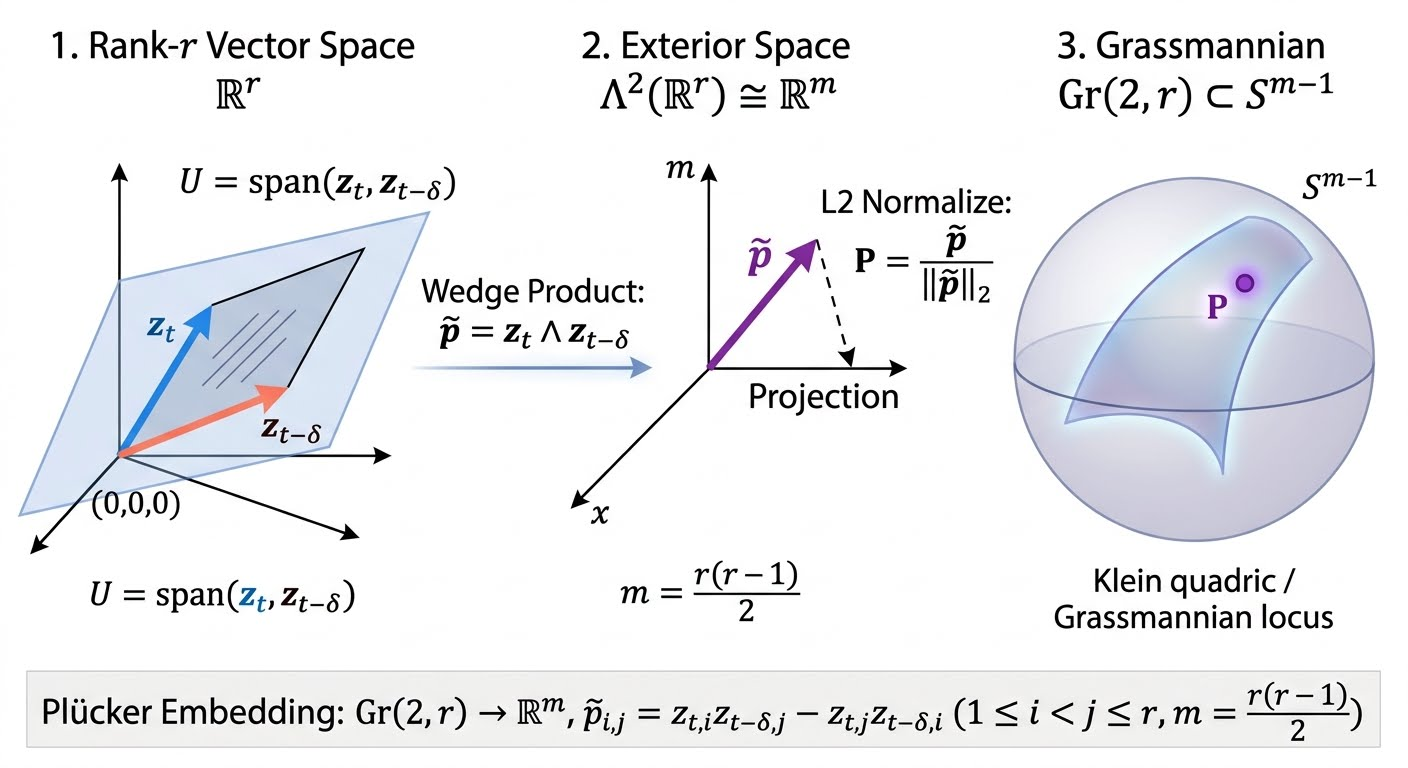

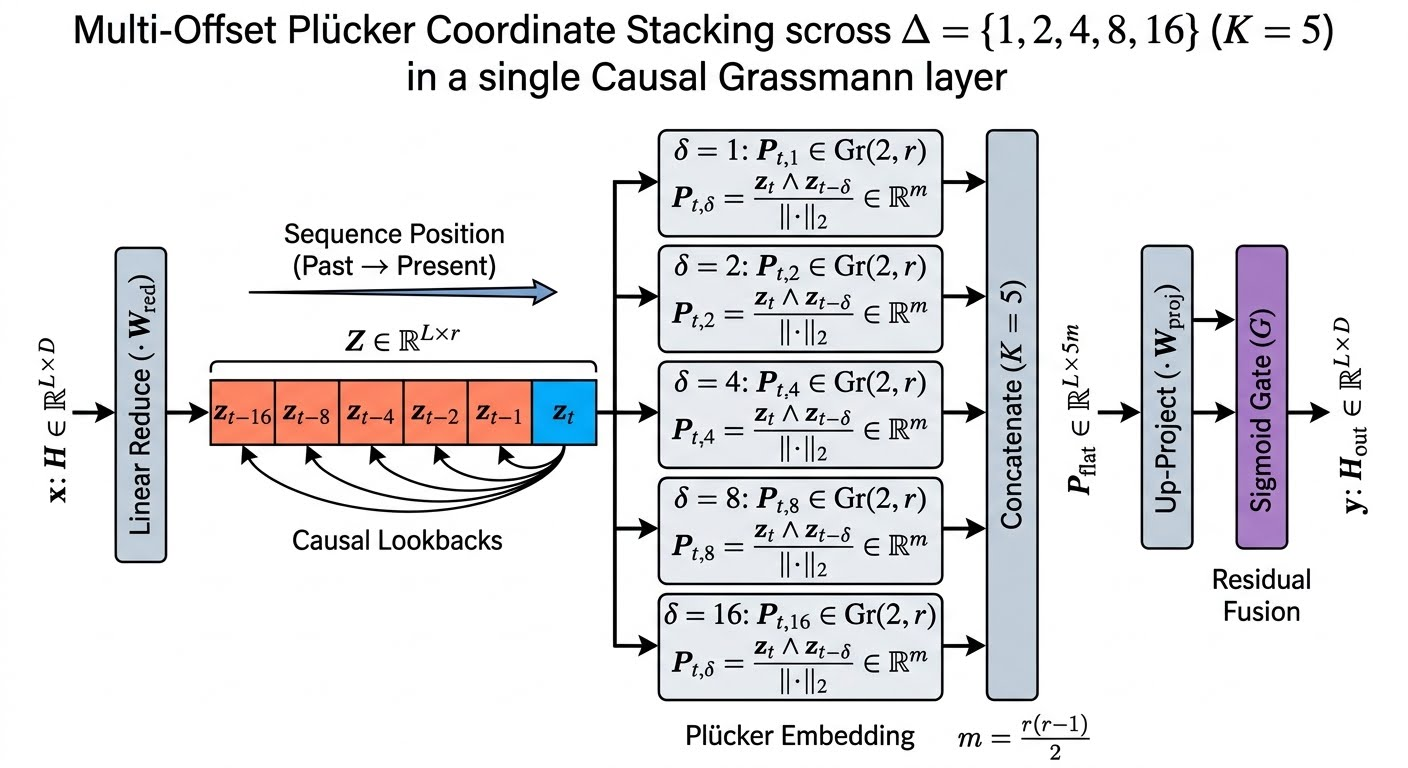

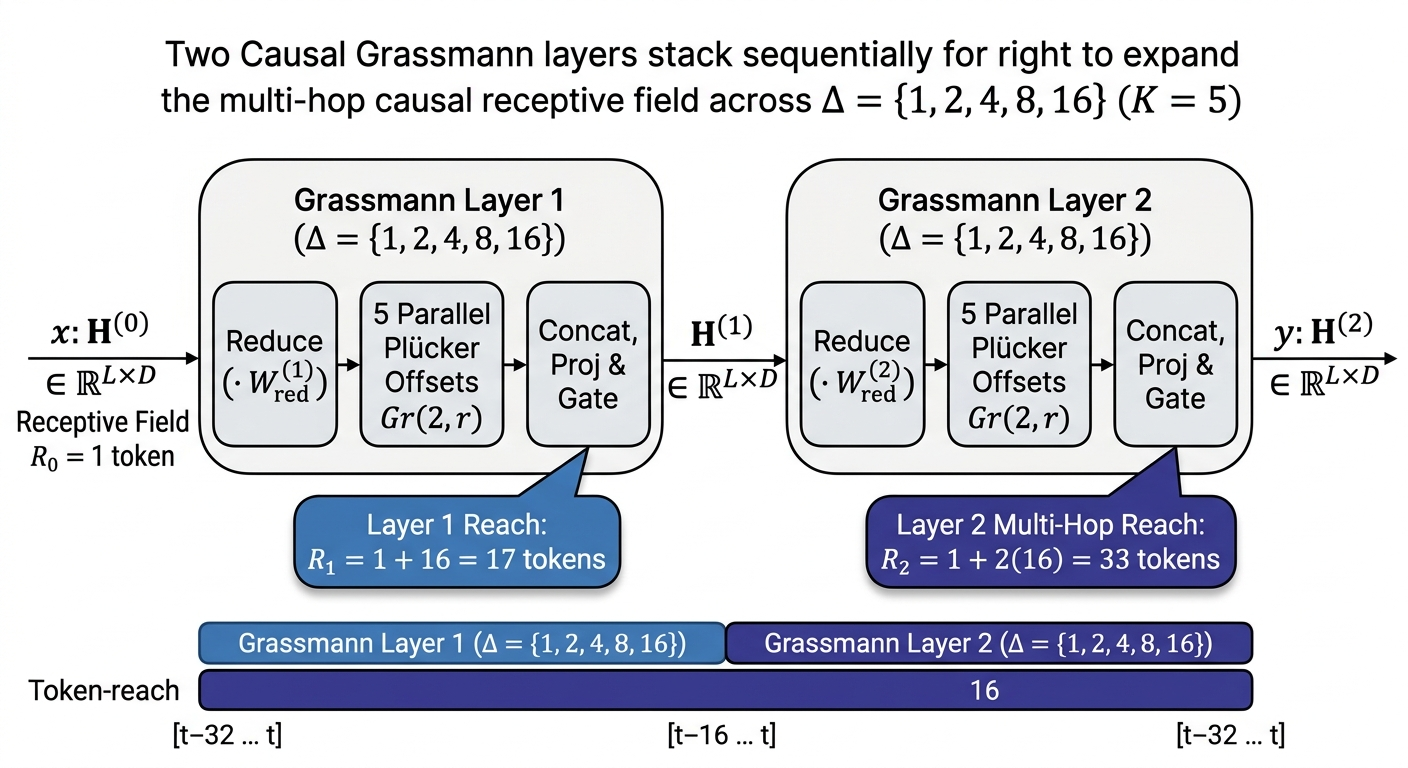

### 💡 ELI5: What is `CausalGrassmannMixer` actually doing?

Imagine you are reading a story, and at each word, you need to remember things that happened in the past to make sense of the current sentence.

#### 1. The Standard Attention Way (Drawing Lines to Everyone)
Normally, **Standard Attention** looks back by drawing a line from the current word to *every single previous word* in the sentence. It calculates a "score" for each connection. If you have $20$ words, each word looks at up to $20$ others. This gets incredibly expensive as sentences get longer ($L \times L$ complexity).

#### 2. The Grassmann Mixer Way (Using 2D Planes to Group Clues)
Instead of drawing lines between individual words, the **Grassmann Mixer** does something highly geometric:

* **Step 1: Simplify (Rank Reduction)**  
  First, it shrinks the big, complex word representations down to a compact space of $16$ simple dimensions ($r=16$). Think of this as translating full paragraphs into $16$ core bullet points.

* **Step 2: Look Back at Fixed Offsets (Dilated Lookback)**  
  It only looks back at specific, smart intervals: **1 step ago, 2 steps ago, 4 steps ago, 8 steps ago, and 16 steps ago** ($\{1, 2, 4, 8, 16\}$). This covers a wide history very cheaply.

* **Step 3: Build 2D Planes (Plücker Coordinates)**  
  For each interval (like "4 steps ago"), it pairs the current word ($z_t$) and the past word ($z_{t-4}$). Together, two vectors define a **2D flat plane** in geometry.
  * To represent this 2D plane mathematically as a single vector, it computes the **wedge product** ($z_t \wedge z_{t-d}$).
  * It maps this plane onto a mathematical map of all possible planes (called the **Grassmannian Manifold**).
  * This gives us a neat, normalized coordinate (the **Plücker Coordinate**) that acts as a "fingerprint" representing the relationship between the current word and that specific past word.

* **Step 4: Blend the Clues (Gated Fusion)**  
  Finally, it collects these relationship fingerprints across all $5$ lookback offsets, projects them back into the main dimensions, and uses a learned gateway (a sigmoid gate) to decide how much of this geometric relationship history to blend into your current token state.

In [4]:
# 4. Architecture 2: Causal Grassmann Subspace Mixing Network (2 Layers, K = 5)
class CausalGrassmannMixer(nn.Module):
    """
    Maps token pairs (z_t, z_{t-delta}) onto Gr(2, r) via normalized Plücker coordinates
    across K=5 exponentially dilated causal offsets: Delta = [1, 2, 4, 8, 16].
    """
    def __init__(self, d_model: int, rank_r: int = 24, offsets=(1, 2, 4, 8, 16), eps: float = 1e-6):
        super().__init__()
        self.d_model = d_model
        self.rank_r = rank_r
        self.offsets = tuple(offsets)
        self.K = len(self.offsets)
        self.m = rank_r * (rank_r - 1) // 2  # Plücker coordinate dimension C(r, 2)
        self.eps = eps

        self.w_red = nn.Linear(d_model, rank_r, bias=False)
        self.w_proj = nn.Linear(self.K * self.m, d_model, bias=False)
        self.w_gate = nn.Linear(2 * d_model, d_model, bias=True)

        # Precompute upper-triangular indices (i < j) for wedge product z_t ∧ z_{t-delta}
        triu_i, triu_j = torch.triu_indices(rank_r, rank_r, offset=1)
        self.register_buffer("triu_i", triu_i, persistent=False)
        self.register_buffer("triu_j", triu_j, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, D = x.shape
        z = self.w_red(x)  # (B, L, r)

        plucker_list = []
        for delta in self.offsets:
            if delta >= L:
                z_shifted = torch.zeros_like(z)
            else:
                pad = torch.zeros(B, delta, self.rank_r, device=z.device, dtype=z.dtype)
                z_shifted = torch.cat([pad, z[:, :-delta, :]], dim=1)

            # Antisymmetric wedge product: p_{ij} = z_{t,i}*z_{t-d,j} - z_{t,j}*z_{t-d,i}
            p_tilde = z[:, :, self.triu_i] * z_shifted[:, :, self.triu_j] - z[:, :, self.triu_j] * z_shifted[:, :, self.triu_i]
            # L2 normalization projects onto unit sphere embedding of Gr(2, r)
            p_norm = p_tilde / (torch.linalg.vector_norm(p_tilde, dim=-1, keepdim=True) + self.eps)
            plucker_list.append(p_norm)  # (B, L, m)

        p_flat = torch.cat(plucker_list, dim=-1)  # (B, L, K * m)
        phi = self.w_proj(p_flat)                 # (B, L, D)
        gate = torch.sigmoid(self.w_gate(torch.cat([x, phi], dim=-1)))
        return gate * x + (1.0 - gate) * phi


class GrassmannBlock(nn.Module):
    def __init__(self, d_model: int, rank_r: int, offsets, d_ff: int):
        super().__init__()
        self.norm1 = RMSNorm(d_model)
        self.mixer = CausalGrassmannMixer(d_model, rank_r=rank_r, offsets=offsets)
        self.norm2 = RMSNorm(d_model)
        self.ffn = SwiGLUFFN(d_model, d_ff)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.mixer(self.norm1(x)) + x
        x = x + self.ffn(self.norm2(x))
        return x


class GrassmannLM(nn.Module):
    def __init__(self, vocab_size: int, max_len: int, d_model: int, rank_r: int, offsets, d_ff: int, n_layers: int = 2):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([GrassmannBlock(d_model, rank_r, offsets, d_ff) for _ in range(n_layers)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        B, L = idx.shape
        pos = torch.arange(L, device=idx.device).unsqueeze(0)
        x = self.tok_emb(idx) + self.pos_emb(pos)
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.norm_f(x))

### 📐 Dimensional Analysis: Why Project to $r = 16$ Instead of Leaving It at $128$?

When looking at the `CausalGrassmannMixer`, it is natural to ask: *Why project the token dimension down to a low-rank representation $r = 16$ instead of computing the Grassmann wedge products directly on the full hidden dimension $d = 128$?*

The answer lies in the **geometric and combinatorial scaling** of the Plücker coordinates representing $2$-dimensional planes.

---

#### 1. The Combinatorial Explosion of Plücker Coordinates
When we compute the skew-symmetric wedge product ($z_t \wedge z_{t-\delta}$) to find the unique coordinate fingerprint of the $2D$ plane spanned by two vectors in $\mathbb{R}^r$, the resulting Plücker vector has a dimension of:

$$m = \binom{r}{2} = \frac{r(r - 1)}{2}$$

Let's calculate the size of this representation at both dimensions:

* **With Low-Rank Projection ($r = 16$):**
  $$m = \frac{16 \times 15}{2} = 120 \text{ coordinates per offset}$$
* **Without Projection ($r = 128$):**
  $$m = \frac{128 \times 127}{2} = 8,128 \text{ coordinates per offset}$$

---

#### 2. Parameter Explosion at the Fusion Step
After calculating the coordinates across all $K = 5$ dilated offsets, we concatenate them and project them back to the hidden dimension $D = 128$ using the projection layer `w_proj`.

$$\text{Shape of } P_{\text{flat}} = (B, L, K \cdot m)$$

Let's compare the parameter footprint of `w_proj` for both configurations:

* **With Low-Rank Projection ($r = 16$):**
  * Inputs to `w_proj`: $5 \text{ offsets} \times 120 = 600$ features.
  * Weight Matrix Dimensions: $600 \to 128$.
  * **Parameters:** $600 \times 128 = \mathbf{76,800}$ parameters.

* **Without Projection ($r = 128$):**
  * Inputs to `w_proj`: $5 \text{ offsets} \times 8,128 = 40,640$ features.
  * Weight Matrix Dimensions: $40,640 \to 128$.
  * **Parameters:** $40,640 \times 128 = \mathbf{5,201,920}$ parameters!

Leaving the representation at $128$ would increase the parameters of this single layer by **nearly 7,000%**, causing the model to completely lose its lightweight efficiency and likely overfit instantly on small datasets.

---

#### Summary of the Trade-Off

| Attribute | Projected ($r=16$) | Unprojected ($r=128$) |
| :--- | :--- | :--- |
| **Plücker Dimension per Offset ($m$)** | $120$ | $8,128$ |
| **Concatenated Size ($K \cdot m$)** | $600$ | $40,640$ |
| **Projection Layer Parameters (`w_proj`)** | **$76.8\text{K}$** | **$5.20\text{M}$** |
| **Geometric Interpretation** | Focuses on a noise-robust, highly compressed $2D$ subspace. | Highly redundant, noisy, and computationally prohibitive. |

### ⚖️ Architectural Trade-offs: Causal Grassmann vs. Standard Causal Self-Attention

To help you decide when to use which mechanism, here is a detailed breakdown of the structural, mathematical, and practical pros and cons of both architectures.

---

### 1. Standard Causal Self-Attention

| **Pros** | **Cons** |
| :--- | :--- |
| 🎯 **Complete Receptive Field:** Global context window with no spatial gaps. Every token can query any other token across arbitrary sequence lengths $L$ at full fidelity. | ⚠️ **Quadratic Memory & Speed Scaling:** Memory and processing costs scale at $O(L^2)$. At very long sequence lengths (e.g., $32\text{K}+$ tokens), it becomes computationally prohibitive. |
| 🛠️ **Hardware-Optimized Kernels:** Highly optimized on GPU/TPU hardware via native primitives like FlashAttention, making execution incredibly fast in practice. | 🎛️ **Key-Value (KV) Cache Bloat:** Autoregressive generation requires storing a growing history of Key-Value tensors, leading to high memory pressure during inference. |
| 🧩 **No Hyperparameter Tuning for Space:** Simply operates on projection heads without needing to tune shift offsets or project hidden ranks down to artificial bounds. | |

---

### 2. Causal Grassmann Mixer

| **Pros** | **Cons** |
| :--- | :--- |
| ⚡ **Linear Scaling $O(L \cdot K)$:** Complexity scales linearly with sequence length because the number of lookback offsets ($K$) is constant. Ideal for scaling to massive sequences. | ❌ **Receptive Field Gaps:** Can only see historical steps matching the fixed, dilated offsets (e.g., $1, 2, 4, 8, 16$). Missing steps must be learned across multiple composed layers. |
| 💾 **Constant Memory Footprint:** No full pairwise attention score matrix of size $L \times L$ is ever materialized in memory. | 🐌 **Lacks Custom Hardware Optimization:** Relies on shift and wedge product loop operations in standard PyTorch, making it slower to run on standard hardware compared to optimized FlashAttention. |
| 🌀 **Geometric Robustness:** Projects pairs into coordinate systems mapping invariant 2D planes on a Grassmannian manifold, extracting stable subspace features. | 📉 **Information Loss (Bottleneck):** Projecting representation dimensions down to $r = 16$ or $r = 24$ can discard fine-grained local context details. |

---

### 🏁 Decision Matrix: When to use which?

* **Use Standard Causal Self-Attention if:**
  * You are working on standard sequence lengths (e.g., $L \le 8,192$).
  * Your task requires dense, high-fidelity associative recall where *every single word* in history might contain the crucial prediction cue.
  * You want to maximize training throughput using raw GPU-accelerated code (FlashAttention).

* **Use Causal Grassmann Subspace Mixing if:**
  * You are scaling to exceptionally long contexts where $O(L^2)$ memory allocations fail.
  * Your sequence patterns are structured or periodic, fitting well within predictable dilated intervals.
  * You want to restrict model memory usage to linear capacity during inference.

### 🔍 Receptive Completeness: Standard Causal Self-Attention vs. Causal Grassmann Mixer. Does the grassman find context as complete as the Standard Causal Self-Attention?

The short answer is **no, the Causal Grassmann Mixer is not as contextually 'complete' as Standard Causal Self-Attention**, but it is designed that way on purpose as a specific, mathematically sound trade-off.

Here is how they compare in terms of capturing historical context:

---

#### 1. Standard Causal Self-Attention: "Fully Complete" $O(L^2)$
Standard self-attention is complete and lossless over the sequence length because it builds a comprehensive pairwise correlation matrix of size $L \times L$.

* **Capability:** Every token $t$ can query any arbitrary past token $t-d$ (even if $d=13$, $d=15$, etc.) with equal resolution. There are no gaps in its historical sight line.
* **Cost:** This absolute completeness is what causes the quadratic $O(L^2)$ computational and memory bottleneck as sequence length $L$ scales.

---

#### 2. Causal Grassmann Mixer: "Structural Approximation" $O(L \cdot K)$
The Causal Grassmann Mixer sacrifices absolute completeness to achieve linear efficiency by making two specific architectural assumptions:

* **Discrete Receptive Gaps:** It only looks back at fixed, exponentially dilated offsets $\Delta = \{1, 2, 4, 8, 16\}$. If the key clue to predict $y_t$ lies exactly at $t-11$ or $t-13$, the model **cannot** see it directly in a single layer. It must rely on multi-layer composition (e.g., Layer 1 shifts by $8$ and Layer 2 shifts by $4$ to reach $12$).
* **Low-Rank Projection (Information Compression):** Standard attention works directly on the head-dimension projections. The Grassmann Mixer projects the entire hidden space down to a low-rank space ($r = 16$) before pairing tokens. While this low-rank subspace represents a robust geometric plane (the Grassmannian), fine-grained token features are inherently compressed (and slightly lost) during this projection.


### 5. Model Instantiation & Benchmarking Task

* **`generate_batch`:** Generates synthetic sequence batches where target tokens are created via modular, multi-hop lookback rules:
  $$y_t = (x_{t-1} + 2x_{t-4} + 3x_{t-12}) \pmod{\text{vocab}\_\text{size}}$$
  This is a challenging synthetic test designed to evaluate whether the networks can successfully compose short-range ($t-1$), mid-range ($t-4$), and long-range ($t-12$) historical contexts.
* **`train_and_benchmark`:** Performs 350 optimization steps with AdamW, measures training wall-clock time, and computes both overall token prediction accuracy and long-hop accuracy ($t \ge 12$).

In [5]:
# 5. Instantiate Matched 2-Layer Models (L = 20, K = 5) & Compare Parameter Budgets
SEQ_LEN = 20
N_LAYERS = 2
VOCAB_SIZE = 32
D_MODEL = 128
D_FF = 320
N_HEADS = 4
RANK_R = 16              # m = 16*15/2 = 120 Plücker coords per offset
OFFSETS = (1, 2, 4, 8, 16)  # K = 5 exponentially dilated offsets

attn_model = StandardAttnLM(VOCAB_SIZE, SEQ_LEN, D_MODEL, N_HEADS, D_FF, n_layers=N_LAYERS).to(device)
grass_model = GrassmannLM(VOCAB_SIZE, SEQ_LEN, D_MODEL, RANK_R, OFFSETS, D_FF, n_layers=N_LAYERS).to(device)

def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Sequence Length (L): {SEQ_LEN} | Layers (N): {N_LAYERS} | Grassmann Offsets (K={len(OFFSETS)}): {OFFSETS}")
print(f"Standard Causal Attention Model Parameters: {count_params(attn_model):,}")
print(f"Causal Grassmann (K=5) Model Parameters:    {count_params(grass_model):,}")

Sequence Length (L): 20 | Layers (N): 2 | Grassmann Offsets (K=5): (1, 2, 4, 8, 16)
Standard Causal Attention Model Parameters: 388,224
Causal Grassmann (K=5) Model Parameters:    480,640



### 6. Synthetic Task & Side-by-Side Training

* **`generate_batch`:** Generates synthetic sequence batches where target tokens are created via modular, multi-hop lookback rules:
  $$y_t = (x_{t-1} + 2x_{t-4} + 3x_{t-12}) \pmod{\text{vocab}\_\text{size}}$$
  This is a challenging synthetic test designed to evaluate whether the networks can successfully compose short-range ($t-1$), mid-range ($t-4$), and long-range ($t-12$) historical contexts.
* **`train_and_benchmark`:** Performs 350 optimization steps with AdamW, measures training wall-clock time, and computes both overall token prediction accuracy and long-hop accuracy ($t \ge 12$).

In [6]:
# 6. Side-by-Side Training & Evaluation on a 20-Token Causal Sequence Task
# Task: Given 20 tokens, at every position t >= 4, predict a modular combination of
# tokens at exact lookback distances (t-1), (t-4), and (t-12) — requiring multi-hop
# context composition across the 2 layers.

def generate_batch(batch_size: int = 128, seq_len: int = 20, vocab_size: int = 32):
    x = torch.randint(0, vocab_size, (batch_size, seq_len), device=device)
    y = x.clone()
    for t in range(seq_len):
        t1 = x[:, t - 1] if t >= 1 else 0
        t4 = x[:, t - 4] if t >= 4 else 0
        t12 = x[:, t - 12] if t >= 12 else 0
        y[:, t] = (t1 + 2 * t4 + 3 * t12) % vocab_size
    return x, y

def train_and_benchmark(model: nn.Module, name: str, steps: int = 350, lr: float = 3e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    for step in range(steps):
        xb, yb = generate_batch(128, SEQ_LEN, VOCAB_SIZE)
        logits = model(xb)
        loss = F.cross_entropy(logits.view(-1, VOCAB_SIZE), yb.view(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0

    model.eval()
    with torch.no_grad():
        xv, yv = generate_batch(512, SEQ_LEN, VOCAB_SIZE)
        preds = model(xv).argmax(dim=-1)
        overall_acc = (preds == yv).float().mean().item() * 100.0
        long_hop_acc = (preds[:, 12:] == yv[:, 12:]).float().mean().item() * 100.0

    return {
        "name": name,
        "params": count_params(model),
        "train_sec": elapsed,
        "final_loss": loss.item(),
        "overall_acc": overall_acc,
        "long_hop_acc": long_hop_acc,
    }

res_attn = train_and_benchmark(attn_model, "Standard Causal Attention (2L)")
res_grass = train_and_benchmark(grass_model, "Causal Grassmann (2L, K=5)")

print(f"{'Model':<32} | {'Params':>9} | {'Time (s)':>8} | {'Loss':>6} | {'All Pos Acc':>11} | {'t>=12 Acc':>9}")
print("-" * 88)
for r in (res_attn, res_grass):
    print(f"{r['name']:<32} | {r['params']:>9,} | {r['train_sec']:>8.2f} | {r['final_loss']:>6.3f} | {r['overall_acc']:>10.2f}% | {r['long_hop_acc']:>8.2f}%")

Model                            |    Params | Time (s) |   Loss | All Pos Acc | t>=12 Acc
----------------------------------------------------------------------------------------
Standard Causal Attention (2L)   |   388,224 |    65.33 |  2.263 |      25.17% |     6.01%
Causal Grassmann (2L, K=5)       |   480,640 |   166.39 |  2.194 |      29.18% |     2.95%
